In [3]:
import numpy as np
import pandas as pd

# 1. Semilla para asegurar reproducibilidad
np.random.seed(42)
n = 15000

# 2. Identificador
id_cliente = [f"COP-{100000 + i}" for i in range(n)]

# 3. Demografía
edad = np.clip(np.random.normal(loc=38, scale=12, size=n).astype(int), 18, 75)
genero = np.random.choice(['Femenino', 'Masculino'], size=n, p=[0.54, 0.46])
estado_civil = np.random.choice(['Soltero', 'Casado', 'Union_Libre', 'Divorciado', 'Viudo'], size=n, p=[0.35, 0.40, 0.15, 0.07, 0.03])
tipo_empleo = np.random.choice(['Informal', 'Formal', 'Independiente', 'Pensionado'], size=n, p=[0.52, 0.30, 0.13, 0.05])

# 4. Solvencia
ingreso_base = np.random.lognormal(mean=9.3, sigma=0.55, size=n)
ingreso_mensual_estimado = np.round(np.clip(ingreso_base, 3500, 65000), 2)
antiguedad_cliente_meses = np.clip(np.random.exponential(scale=36, size=n).astype(int) + 1, 1, 240)

# 5. Score Base
score_base = 550 + (ingreso_mensual_estimado / 1000) * 4 + (antiguedad_cliente_meses * 0.8) + np.random.normal(0, 50, n)
if_informal_penalty = np.where(tipo_empleo == 'Informal', -30, 0)
score_crediticio_interno = np.clip((score_base + if_informal_penalty).astype(int), 300, 850)

# 6. Variables Financieras
limite_credito_autorizado = np.round(np.clip(score_crediticio_interno * 50 + (ingreso_mensual_estimado * 1.5) + np.random.normal(0, 3000, n), 3000, 100000), -2)
utilizacion_pct = np.random.beta(a=2, b=2, size=n)
utilizacion_linea_credito_pct = np.round(np.clip(utilizacion_pct, 0.05, 0.98), 4)
saldo_pendiente_total = np.round(limite_credito_autorizado * utilizacion_linea_credito_pct, 2)
plazo_credito_quincenas = np.random.choice([12, 18, 24, 36, 48], size=n, p=[0.25, 0.20, 0.35, 0.12, 0.08])
monto_abono_quincenal = np.round((saldo_pendiente_total / plazo_credito_quincenas) * 1.25, 2)

# 7. Comportamiento y Ecosistema
num_compras_ultimos_6m = np.random.poisson(lam=4.5, size=n)
pct_ropa = np.round(np.random.uniform(0.1, 0.9, size=n), 2)
pct_muebles_elect = np.round(1.0 - pct_ropa, 2)
uso_app_coppel = np.random.choice(['Sin_Uso', 'Ocasional', 'Frecuente', 'Muy_Frecuente'], size=n, p=[0.35, 0.30, 0.22, 0.13])
canal_pago_preferente = np.random.choice(['Caja_Tienda', 'App_Coppel', 'OXXO_Terceros', 'Cajero_Automatico'], size=n, p=[0.55, 0.25, 0.12, 0.08])
num_atrasos_1_15_dias_ult_12m = np.random.poisson(lam=1.2, size=n)
num_atrasos_16_30_dias_ult_12m = np.random.poisson(lam=0.4, size=n)
num_prestamos_personales_activos = np.random.choice([0, 1, 2, 3], size=n, p=[0.60, 0.28, 0.09, 0.03])
tiene_cuenta_bancoppel = np.random.choice([0, 1], size=n, p=[0.42, 0.58])
tiene_afore_coppel = np.random.choice([0, 1], size=n, p=[0.70, 0.30])
region_geografica = np.random.choice(['Noroeste', 'Norte', 'Centro', 'Occidente', 'Sur'], size=n, p=[0.20, 0.20, 0.30, 0.18, 0.12])

# 8. Variable Objetivo Compleja (Estocástica y No Lineal)
# Curva de riesgo por edad (jóvenes y adultos mayores con mayor volatilidad)
edad_factor = np.where(edad < 25, 0.45, np.where(edad > 60, 0.30, -0.20))

# Interacción de ingreso y tipo de empleo
emp_factor = np.where(tipo_empleo == 'Informal', 0.50,
             np.where(tipo_empleo == 'Independiente_Comerciante', 0.30,
             np.where(tipo_empleo == 'Pensionado', -0.15, -0.35)))

# Estrés de pago (No lineal)
pti = monto_abono_quincenal / ((ingreso_mensual_estimado / 2.0) + 1.0)
pti_factor = np.where(pti > 0.35, 1.2, np.where(pti > 0.20, 0.5, -0.4))

# Uso de crédito
util_factor = np.where(utilizacion_linea_credito_pct > 0.80, 1.1, np.where(utilizacion_linea_credito_pct > 0.50, 0.3, -0.5))

# Impacto de historial y ecosistema
delinq_factor = num_atrasos_16_30_dias_ult_12m * 0.85 + num_atrasos_1_15_dias_ult_12m * 0.25
app_factor = np.where(uso_app_coppel == 'Muy_Frecuente', -0.5, np.where(uso_app_coppel == 'Frecuente', -0.3, 0.2))
bancoppel_factor = np.where(tiene_cuenta_bancoppel == 1, -0.35, 0.1)
region_factor = np.where(region_geografica == 'Sur', 0.20, np.where(region_geografica == 'Centro', 0.10, -0.10))

# Riesgo Latente con inyección de choque estocástico severo (Distribución Gumbel)
latente = (
    -1.8 + edad_factor + emp_factor + pti_factor + util_factor +
    delinq_factor + app_factor + bancoppel_factor + region_factor -
    (score_crediticio_interno - 600) * 0.005 +
    np.random.gumbel(loc=0, scale=0.8, size=n)
)

# Calibración a tasa de morosidad real en el sector popular (~12%)
prob = 1 / (1 + np.exp(-latente))
threshold = np.percentile(prob, 88.0) # Tomar el 12% superior como default
incumplimiento_quincenal_proximo = (prob >= threshold).astype(int)

# 9. Creación del DataFrame
df = pd.DataFrame({
    'id_cliente': id_cliente,
    'edad': edad,
    'genero': genero,
    'estado_civil': estado_civil,
    'tipo_empleo': tipo_empleo,
    'ingreso_mensual_estimado': ingreso_mensual_estimado,
    'antiguedad_cliente_meses': antiguedad_cliente_meses,
    'score_crediticio_interno': score_crediticio_interno,
    'limite_credito_autorizado': limite_credito_autorizado,
    'utilizacion_linea_credito_pct': utilizacion_linea_credito_pct,
    'saldo_pendiente_total': saldo_pendiente_total,
    'plazo_credito_quincenas': plazo_credito_quincenas,
    'monto_abono_quincenal': monto_abono_quincenal,
    'num_compras_ultimos_6m': num_compras_ultimos_6m,
    'pct_compras_ropa': pct_ropa,
    'pct_compras_muebles_elect': pct_muebles_elect,
    'uso_app_coppel': uso_app_coppel,
    'canal_pago_preferente': canal_pago_preferente,
    'num_atrasos_1_15_dias_ult_12m': num_atrasos_1_15_dias_ult_12m,
    'num_atrasos_16_30_dias_ult_12m': num_atrasos_16_30_dias_ult_12m,
    'num_prestamos_personales_activos': num_prestamos_personales_activos,
    'tiene_cuenta_bancoppel': tiene_cuenta_bancoppel,
    'tiene_afore_coppel': tiene_afore_coppel,
    'region_geografica': region_geografica,
    'incumplimiento_quincenal_proximo': incumplimiento_quincenal_proximo
})

# Exportar a CSV localmente
#df.to_csv('dataset_coppel_calibrado.csv', index=False)

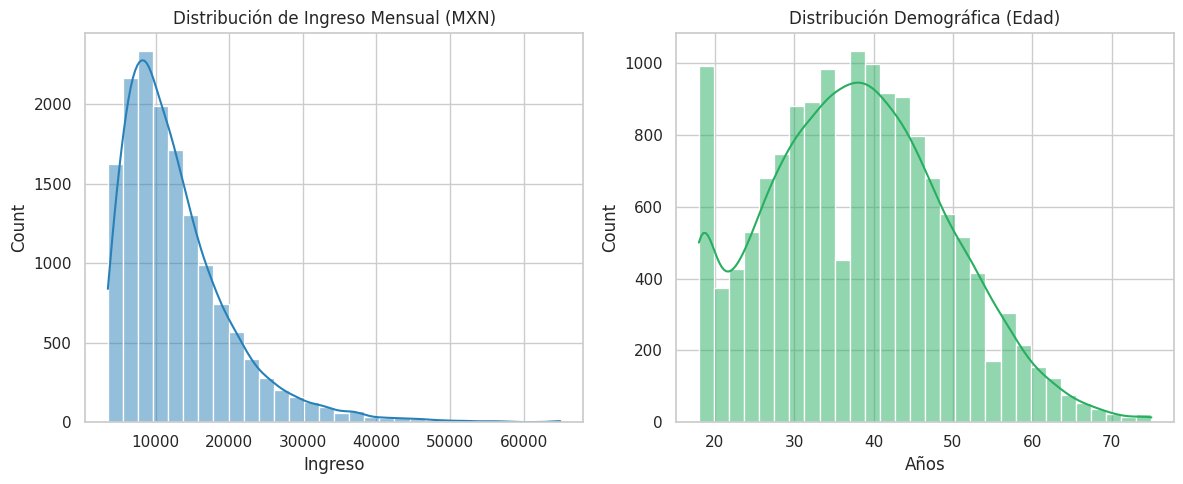

/tmp/ipykernel_382/1286769379.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='tipo_empleo', y='incumplimiento_quincenal_proximo', data=df, errorbar=None, palette='viridis')


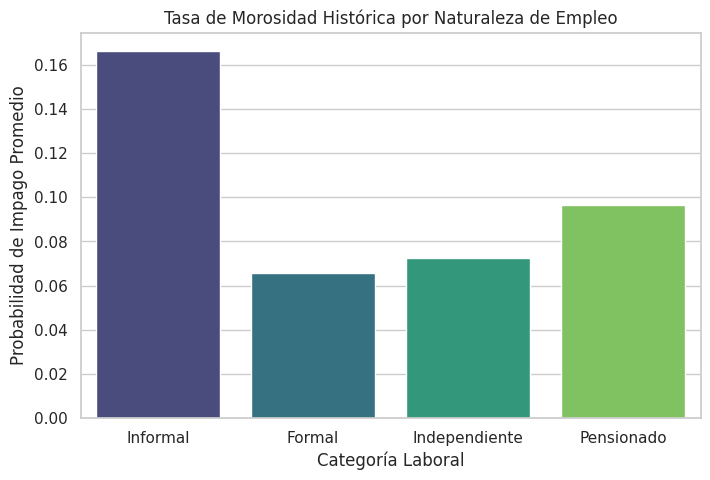

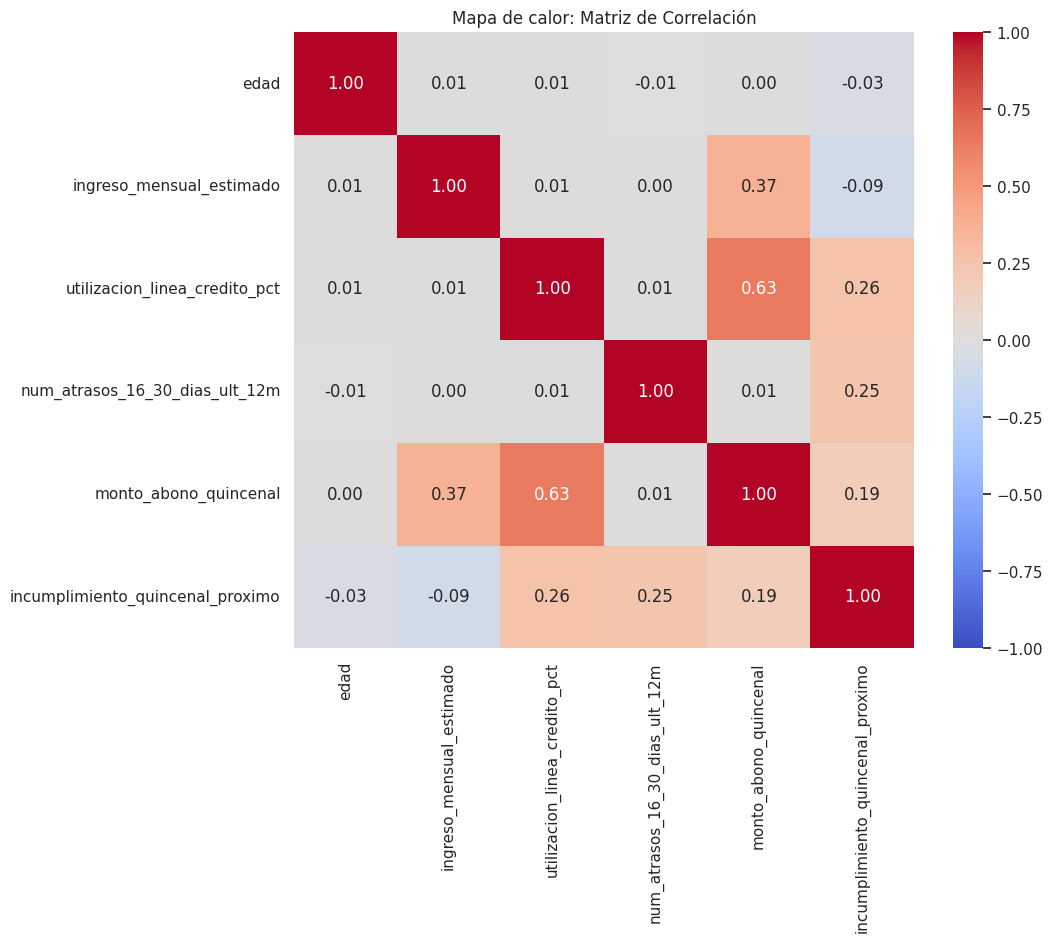

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración del estilo visual
sns.set_theme(style="whitegrid")

# 1. Distribuciones de Ingreso y Edad
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(df['ingreso_mensual_estimado'], bins=30, kde=True, ax=axes[0], color='#2980b9')
axes[0].set_title('Distribución de Ingreso Mensual (MXN)')
axes[0].set_xlabel('Ingreso')

sns.histplot(df['edad'], bins=30, kde=True, ax=axes[1], color='#27ae60')
axes[1].set_title('Distribución Demográfica (Edad)')
axes[1].set_xlabel('Años')
plt.tight_layout()
plt.show()

# 2.Morosidad por Tipo de Empleo
plt.figure(figsize=(8, 5))
sns.barplot(x='tipo_empleo', y='incumplimiento_quincenal_proximo', data=df, errorbar=None, palette='viridis')
plt.title('Tasa de Morosidad Histórica por Naturaleza de Empleo')
plt.ylabel('Probabilidad de Impago Promedio')
plt.xlabel('Categoría Laboral')
plt.show()

# 3. Matriz de Correlación
plt.figure(figsize=(10, 8))
cols_corr = ['edad', 'ingreso_mensual_estimado', 'utilizacion_linea_credito_pct',
             'num_atrasos_16_30_dias_ult_12m', 'monto_abono_quincenal', 'incumplimiento_quincenal_proximo']
sns.heatmap(df[cols_corr].corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Mapa de calor: Matriz de Correlación')
plt.show()